# Rain, an atom at zero

On a given day some rain gauges record nothing. Daily rain is a mixture of a point mass at zero, the dry
places, and a spread of positive amounts where it rained. An interpolator that averages turns every dry
place near a wet one into a little rain, so its map is never dry. Here we see this on a simulated field
whose dry places we know, then on the rain gauges of the Maipo basin in central Chile, where we ask the
probabilistic decoders what the averaging ones cannot tell.

## What you will learn

- Why an averaging decoder dilutes the dry places, and how the members of a drawing decoder keep them.
- How to read the probability of a dry day, and of heavy rain, from the members.
- How the probabilistic decoders compare with the averaging ones on real gauges, by the CRPS and by the
  coverage of their intervals under cross-validation.
- What `empty_cells` changes in the parts of a basin far from every gauge.
- What elevation adds, as a third coordinate.

*What can an ensemble say about where it did not rain?*

## The idea

The law of the value at a location, as an ensemble gives it, is the spread of its members. An averaging
decoder, IDW or kriging, gives each partition a weighted mean of the data of the cell, which is zero only
if every datum of the cell is zero. Its members are therefore almost never zero, however many dry gauges
surround the location. A drawing decoder gives each partition one datum of the cell, drawn uniformly
(`draw`) or with the weights of an averaging decoder (`wdraw_idw`, `wdraw_kriging`,
`wdraw_adaptiveidw`, `wdraw_sharpidw`). Its members are observed values, zeros included, so the share
of members at zero estimates the probability that the location was dry.

The weighted draw of an averaging decoder picks each datum with that decoder's weight, so the mean of
its members approaches the averaging decoder's map. The law around it changes. The tutorial on the probabilistic decoders explains them in detail. The book behind Spatialize treats rain as one of its situations, an atom the averaging decoders cannot carry.

## Part 1. A simulated rain field

### A field with dry patches

The field is a Voronoi block-mark field on the unit square. Thirty-five cells each receive one value,
zero with probability 0.45 and otherwise a lognormal amount. We know where it is dry, and draw 400
gauges at random.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import spatialize
from spatialize.data import load_precipitation_maipo
from spatialize.gs.esi import esi_griddata, esi_nongriddata, esi_pareto_hparams_search
import spatialize.gs.esi.scorefunction as sf

spatialize.session.set(empty_cells="coarsen", progress=False)

m = 64
grid = (np.arange(m) + 0.5) / m
nodes = np.stack(np.meshgrid(grid, grid), -1).reshape(-1, 2)        # maps are [y, x]
xi = np.stack(np.meshgrid(grid, grid))

rng = np.random.default_rng(4)
nuclei = rng.random((35, 2))
marks = np.where(rng.random(35) >= 0.45, rng.lognormal(1.0, 0.7, 35), 0.0)

def rain(x):
    return marks[np.argmin(((x[:, None, :] - nuclei[None]) ** 2).sum(-1), axis=1)]

truth = rain(nodes).reshape(m, m)
dry = truth == 0
gauges = rng.random((400, 2))
amounts = rain(gauges)
print(f"dry share of the field {dry.mean():.2f}, of the gauges {(amounts == 0).mean():.2f}")

dry share of the field 0.46, of the gauges 0.47


### The averaging map against the drawing members

The Pareto search chooses the granularity for IDW, a fair decoder on a field without a preferred
direction. With the same partitions we run the uniform draw and the weighted draw of IDW. From each
ensemble we read the map, the mean of the members, and the share of members at zero.

In [2]:
search = esi_pareto_hparams_search(gauges, amounts, local_interpolator="idw", n_partitions=[100],
                                   alpha=[0.7, 0.8, 0.9, 0.95, 0.98], exponent=[2.0], k="loo",
                                   scoring=sf.mae, seed=0)
alpha = search.best_result(strategy="knee")["alpha"]
print(f"alpha at the knee {alpha}")

simulated = {}
for name, decoder in (("IDW", dict(local_interpolator="idw", exponent=2.0)),
                      ("uniform draw", dict(local_interpolator="draw")),
                      ("weighted draw", dict(local_interpolator="wdraw_idw", exponent=2.0))):
    members = esi_griddata(gauges, amounts, xi, n_partitions=200, alpha=alpha, seed=0, **decoder).esi_samples()
    simulated[name] = {"map": members.mean(-1), "p_dry": (members == 0).mean(-1)}

rows = {}
for name, r in simulated.items():
    guess = r["p_dry"] > 0.5
    rows[name] = {"dry share of the map": (r["map"] == 0).mean(),
                  "mean probability of dry": r["p_dry"].mean(),
                  "overlap with the dry region": (guess & dry).sum() / (guess | dry).sum()}
rows["truth"] = {"dry share of the map": dry.mean(), "mean probability of dry": dry.mean(),
                 "overlap with the dry region": 1.0}
pd.DataFrame(rows).T.round(3)

alpha at the knee 0.98


,dry share of the map,mean probability of dry,overlap with the dry region
IDW,0.000,0.356,0.718
uniform draw,0.007,0.461,0.825
weighted draw,0.040,0.460,0.829
truth,0.460,0.460,1.000


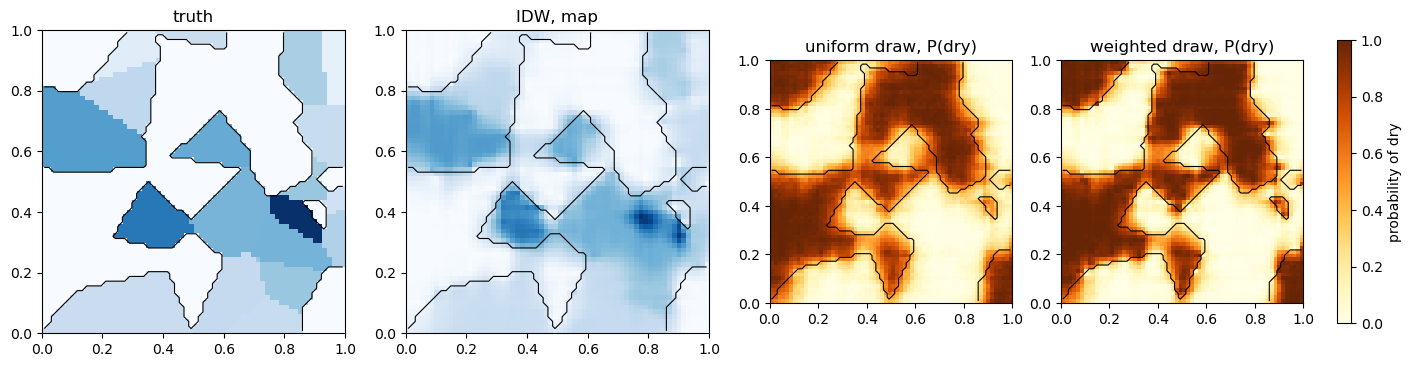

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4.6))
panels = [("truth", truth, "Blues", None), ("IDW, map", simulated["IDW"]["map"], "Blues", None),
          ("uniform draw, P(dry)", simulated["uniform draw"]["p_dry"], "YlOrBr", (0, 1)),
          ("weighted draw, P(dry)", simulated["weighted draw"]["p_dry"], "YlOrBr", (0, 1))]
for ax, (title, z, cmap, lim) in zip(axes, panels):
    im = ax.imshow(z, origin="lower", extent=(0, 1, 0, 1), cmap=cmap,
                   vmin=None if lim is None else lim[0], vmax=None if lim is None else lim[1])
    ax.contour(grid, grid, dry.astype(float), levels=[0.5], colors="black", linewidths=0.8)
    ax.set_title(title)
fig.colorbar(im, ax=axes[2:], shrink=0.8, label="probability of dry")
plt.show()

The black line bounds the true dry region. The IDW map has no dry location at all, since every
location near a wet cell receives some rain, while its members are zero far less often than the field is
dry. The members of both draws are zero about as often as the field is dry, and the region where a dry
day is more likely than not follows the true one. The weighted draw matches it a little better, its
weights favouring the gauges nearest to each location.

## Part 2. The rain gauges of the Maipo basin

### The data

The Maipo basin rises from the coast to the high Andes, above 6 000 m. Its 69 rain gauges lie mostly in
the valley, so most of the basin lies far from any gauge. We have three days of July 2018. On each,
between a tenth and a quarter of the gauges recorded no rain.

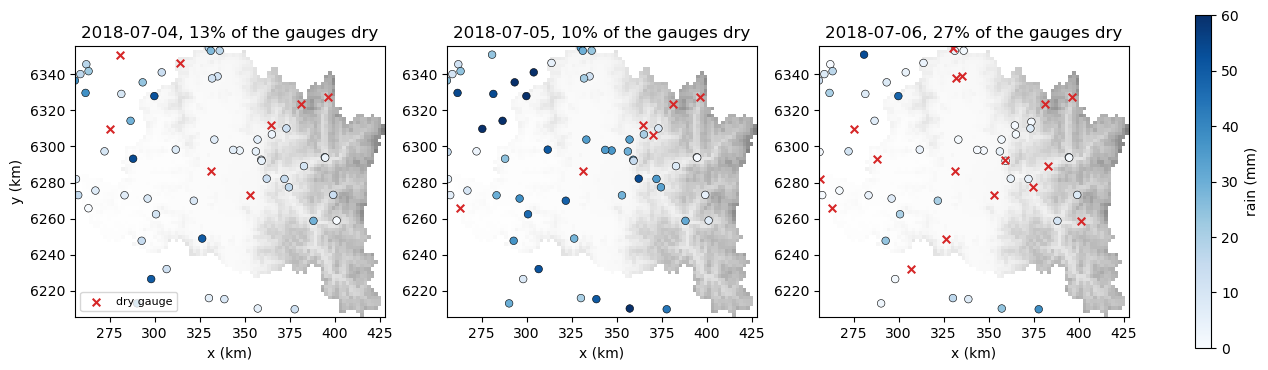

In [4]:
samples, locations = load_precipitation_maipo()
days = ["2018-07-04", "2018-07-05", "2018-07-06"]
X = locations[["x", "y"]].values
xs, ys = np.unique(locations.x), np.unique(locations.y)
extent = (xs[0] / 1e3, xs[-1] / 1e3, ys[0] / 1e3, ys[-1] / 1e3)

def image(values):
    # the basin's values on its 2 km grid, NaN outside the basin
    out = np.full((len(ys), len(xs)), np.nan)
    out[np.searchsorted(ys, locations.y), np.searchsorted(xs, locations.x)] = values
    return out

def day_data(day):
    d = samples.dropna(subset=[day])
    return d[["x", "y"]].values, d[day].values, d

fig, axes = plt.subplots(1, 3, figsize=(17, 5.4))
for ax, day in zip(axes, days):
    P, V, d = day_data(day)
    ax.imshow(image(locations.z), origin="lower", extent=extent, cmap="Greys", alpha=0.5)
    wet = V > 0
    sc = ax.scatter(P[wet, 0] / 1e3, P[wet, 1] / 1e3, c=V[wet], cmap="Blues", s=30, edgecolors="black",
                    linewidths=0.4, vmin=0, vmax=60)
    ax.scatter(P[~wet, 0] / 1e3, P[~wet, 1] / 1e3, marker="x", c="C3", s=30, label="dry gauge")
    ax.set_title(f"{day}, {(~wet).mean():.0%} of the gauges dry")
    ax.set_xlabel("x (km)")
axes[0].set_ylabel("y (km)"); axes[0].legend(loc="lower left", fontsize=8)
fig.colorbar(sc, ax=axes, shrink=0.8, label="rain (mm)")
plt.show()

The grey background is the elevation of the basin, darker higher. The gauges crowd the valley in the
west, while the high Andes in the east hold only a few.

### The averaging decoders

As a reference, the Pareto search chooses the granularity, and the decoder parameters, of IDW, kriging
and adaptive IDW on each day, by their leave-one-out absolute error.

In [5]:
alphas = [0.5, 0.6, 0.7, 0.8, 0.9]
search_kw = dict(n_partitions=[100], alpha=alphas, k="loo", seed=0)

def kriging_grid(V):
    return dict(model=["exponential", "spherical"], range=[10000.0, 30000.0, 60000.0], nugget=[0.0, 10.0],
                sill=[float(V.var())])

averaging = {}
for day in days:
    P, V, _ = day_data(day)
    for name, grid_kw in (("idw", dict(exponent=[1.0, 2.0, 3.0])), ("kriging", kriging_grid(V)), ("adaptiveidw", {})):
        knee = esi_pareto_hparams_search(P, V, local_interpolator=name, scoring=sf.mae, **search_kw,
                                         **grid_kw).best_result(strategy="knee")
        averaging[(day, name)] = knee["decoder_error"]
pd.Series(averaging).unstack().round(2).rename_axis(index="day", columns="leave-one-out MAE (mm)")

leave-one-out MAE (mm),adaptiveidw,idw,kriging
day,,,
2018-07-04,9.59,9.54,9.41
2018-07-05,12.97,13.16,12.72
2018-07-06,6.83,6.89,7.23


The three decoders come within half a millimetre of each other on every day, kriging ahead on two of
them, adaptive IDW on the third. By the error of the map, none stands out on these gauges.

### The probabilistic decoders

The absolute error judges the mean of the members only. To judge the whole law we use the continuous
ranked probability score, the CRPS, which compares the spread of the members with each left-out gauge.
It is in millimetres like the absolute error, to which it reduces when all members coincide. We search
each decoder by the CRPS, then measure how often the interval between the 5 % and 95 % quantiles of the
members holds the left-out gauge, which should be about 90 %.

In [6]:
def loo_members(P, V, decoder):
    out = []
    for i in range(len(V)):
        keep = np.arange(len(V)) != i
        members = esi_nongriddata(P[keep], V[keep], P[i:i + 1], n_partitions=200, seed=0, **decoder).esi_samples()[0]
        out.append(members[np.isfinite(members)])
    return out

def coverage(members, V):
    return np.mean([np.quantile(mm, 0.05) <= v <= np.quantile(mm, 0.95) for mm, v in zip(members, V)])

decoders = {"adaptiveidw": {}, "draw": {}, "wdraw_idw": dict(exponent=[1.0, 2.0, 3.0]), "wdraw_kriging": None,
            "wdraw_adaptiveidw": {}, "wdraw_sharpidw": {}}
chosen, rows = {}, []
for day in days:
    P, V, _ = day_data(day)
    for name, grid_kw in decoders.items():
        grid_kw = kriging_grid(V) if name == "wdraw_kriging" else grid_kw
        knee = esi_pareto_hparams_search(P, V, local_interpolator=name, scoring="crps", **search_kw,
                                         **grid_kw).best_result(strategy="knee")
        decoder = dict(local_interpolator=name, alpha=knee["alpha"], **{k: knee[k] for k in grid_kw})
        chosen[(day, name)] = decoder
        members = loo_members(P, V, decoder)
        rows.append({"day": day, "decoder": name, "CRPS (mm)": np.mean([sf.crps(np.array([v]), mm[None]) for mm, v in zip(members, V)]),
                     "coverage of the 90 % interval": coverage(members, V)})
probabilistic = pd.DataFrame(rows).set_index(["day", "decoder"])
probabilistic.unstack(0).round(2)

CRPS (mm)                        \
day               2018-07-04 2018-07-05 2018-07-06   
decoder                                              
adaptiveidw             8.36      10.35       4.90   
draw                    7.02      10.07       4.80   
wdraw_adaptiveidw       8.27      10.54       4.81   
wdraw_idw               7.05      10.03       4.87   
wdraw_kriging           7.24      10.25       5.02   
wdraw_sharpidw          8.66      10.69       4.95   

                  coverage of the 90 % interval                        
day                                  2018-07-04 2018-07-05 2018-07-06  
decoder                                                                
adaptiveidw                                0.57       0.65       0.49  
draw                                       0.90       0.84       0.89  
wdraw_adaptiveidw                          0.72       0.73       0.73  
wdraw_idw                                  0.80       0.75       0.90  
wdraw_kriging                              0.82       0.71       0.90  
wdraw_sharpidw                             0.79       0.73       0.73

On every day a drawing decoder has the lowest CRPS, the uniform draw or the weighted draw of IDW, ahead
of the averaging adaptive IDW by 1.3 mm on 4 July and by a tenth of a millimetre on 6 July. The coverage
separates them more. The intervals of adaptive IDW hold the left-out gauge only half to two thirds of
the time. The uniform draw comes closest to 90 % on every day, followed by the weighted draws of IDW and
kriging, while those of the two adaptive decoders stay near 73 %.

### What the members say on 6 July

On the driest day we compare the map of adaptive IDW with what the weighted draw of IDW reads from its
members, the probability of a dry day, the probability of more than 20 mm, and the 90th percentile.
Far from the gauges, under `empty_cells="mark"`, a partition whose cell holds no gauge contributes the
value of a nearby cell with data, so the law there keeps the dry gauges too.

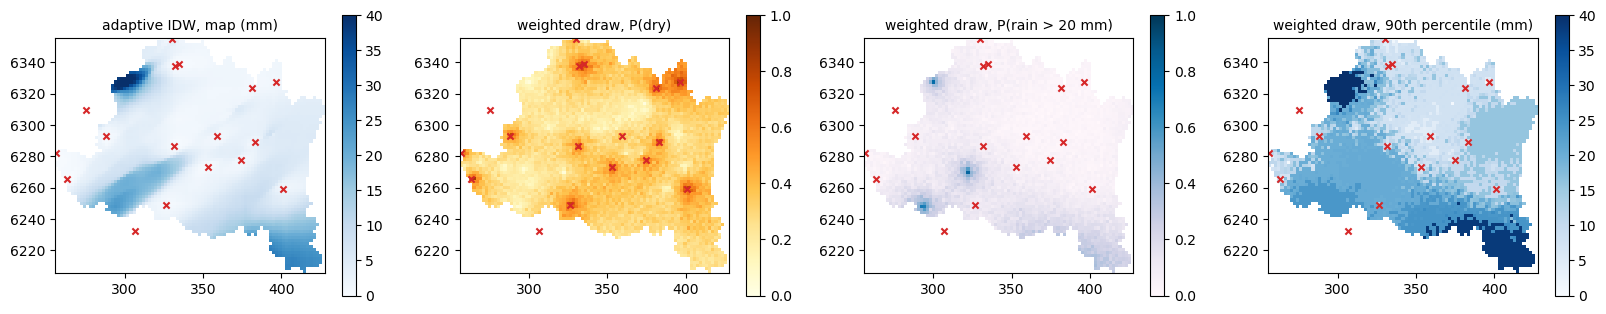

dry share of the gauges 0.27, of the map 0.00, mean P(dry) of the weighted draw 0.31


In [7]:
day = "2018-07-06"
P, V, d = day_data(day)
mean_map = esi_nongriddata(P, V, X, n_partitions=200, seed=0, **chosen[(day, "adaptiveidw")]).estimation()
with spatialize.session.override(empty_cells="mark"):
    drawn = esi_nongriddata(P, V, X, n_partitions=200, seed=0, **chosen[(day, "wdraw_idw")])
members = drawn.esi_samples()
readings = {"adaptive IDW, map (mm)": (mean_map, "Blues", (0, 40)),
            "weighted draw, P(dry)": ((members == 0).mean(1), "YlOrBr", (0, 1)),
            "weighted draw, P(rain > 20 mm)": ((members > 20).mean(1), "PuBu", (0, 1)),
            "weighted draw, 90th percentile (mm)": (np.quantile(members, 0.9, axis=1), "Blues", (0, 40))}
fig, axes = plt.subplots(1, 4, figsize=(20, 5.2))
for ax, (title, (z, cmap, lim)) in zip(axes, readings.items()):
    im = ax.imshow(image(z), origin="lower", extent=extent, cmap=cmap, vmin=lim[0], vmax=lim[1])
    ax.scatter(P[V == 0, 0] / 1e3, P[V == 0, 1] / 1e3, marker="x", c="C3", s=20)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, shrink=0.7)
plt.show()
print(f"dry share of the gauges {np.mean(V == 0):.2f}, of the map {np.mean(mean_map == 0):.2f}, "
      f"mean P(dry) of the weighted draw {np.mean(members == 0):.2f}")

The map of adaptive IDW has no dry location, although 27 % of the gauges recorded no rain. The weighted
draw gives every location a probability of a dry day, highest around the dry gauges and 0.31 on average
over the basin. The probability of more than 20 mm stays low except next to the wettest gauges. The
90th percentile says how much a wet day could bring, about 40 mm in the south-east where the map gives
some 20 mm. Its blocks are the cells of the partitions, since each member is the value of one gauge.

### Far from the gauges

The residual weight, the share of partitions whose cell around a location holds no gauge, grows towards
the Andes. The session setting `empty_cells` decides what those partitions contribute. Under `"nan"`
they contribute nothing, so the law rests on the partitions whose cell reaches a gauge.

In [8]:
high = locations.z.values > 3000
rows = {}
for policy in ("nan", "mark", "coarsen"):
    with spatialize.session.override(empty_cells=policy):
        r = esi_nongriddata(P, V, X, n_partitions=200, seed=0, **dict(chosen[(day, "wdraw_idw")], alpha=0.95))
    mm = r.esi_samples()
    rows[policy] = {"residual weight above 3 000 m": r.empty_cell_fraction()[high].mean(),
                    "P(dry) above 3 000 m": np.nanmean((mm == 0)[high]),
                    "P(rain > 20 mm) above 3 000 m": np.nanmean((mm > 20)[high])}
pd.DataFrame(rows).T.round(2)

,residual weight above 3 000 m,P(dry) above 3 000 m,P(rain > 20 mm) above 3 000 m
nan,0.6,0.19,0.02
mark,0.6,0.41,0.09
coarsen,0.6,0.42,0.11


Above 3 000 m, six partitions in ten have no gauge in the cell of a location at `alpha` = 0.95. Under
`"nan"` those partitions say nothing, so the probability of a dry day falls to 0.19 and that of more than
20 mm to 0.02. The marks and the coarser cells give them the values of nearby gauges, which keeps the two
readings near 0.4 and 0.1.

### Elevation as a third coordinate

Rain depends on elevation as well as on position, so we can estimate on the surface of the basin with
the elevation as a third coordinate, the 2.5D case. Elevation spans a few kilometres against the
basin's 170, so on its own it barely moves a distance. We multiply it by a vertical exaggeration
before searching adaptive IDW and its weighted draw.

In [9]:
rows = {}
for factor in (0, 10, 30):
    P3 = P if factor == 0 else np.column_stack([P, d["z"].values * factor])
    mean_knee = esi_pareto_hparams_search(P3, V, local_interpolator="adaptiveidw", scoring=sf.mae,
                                          **search_kw).best_result(strategy="knee")
    law_knee = esi_pareto_hparams_search(P3, V, local_interpolator="wdraw_adaptiveidw", scoring="crps",
                                         **search_kw).best_result(strategy="knee")
    rows["2D" if factor == 0 else f"elevation × {factor}"] = {
        "adaptive IDW, leave-one-out MAE (mm)": mean_knee["decoder_error"],
        "weighted draw, CRPS (mm)": law_knee["decoder_error"]}
pd.DataFrame(rows).T.round(2)

,"adaptive IDW, leave-one-out MAE (mm)","weighted draw, CRPS (mm)"
2D,6.83,5.23
elevation × 10,6.70,5.29
elevation × 30,6.70,5.20


Elevation lowers the error of adaptive IDW's map by about a tenth of a millimetre and leaves the CRPS of
its weighted draw where it was. Four gauges in five lie below 1 000 m, so the data say little about how
rain changes higher up.

## What can go wrong

- **Reading rain from the map.** The mean of the members is the map of an averaging decoder, never dry
  near a wet gauge. Read the probability of dry from the members of a drawing decoder.
- **Scoring the law by the mean.** The absolute error ignores the spread of the members, so a search
  scored by it cannot tell a law that covers from one that does not. Score probabilistic decoders by the
  CRPS, then check the coverage.
- **Intervals from averaging decoders.** Their members spread only as much as the partitions move the
  weights, so their intervals miss most left-out gauges.
- **`empty_cells="nan"` far from the gauges.** The law there rests on the few partitions whose cell
  reaches a gauge, which understates both a dry day and heavy rain.
- **A few gauges.** With some sixty gauges a day, every score here moves with the seed. Compare
  decoders over several days, as here, before choosing one.

## Try it yourself

1. Raise the dry probability of the simulated field to 0.7 and watch the IDW map.
2. Read the probability of more than 40 mm on 5 July, the wettest day.
3. Use `empty_cells="coarsen"` for the readings and compare the high Andes.
4. Search the weighted draw of IDW with elevation as a third coordinate.

## Next

- *The probabilistic decoders*, for the drawing decoders and their readings in detail.
- *Cells without data*, for `empty_cells` and the residual weight.
- *Heavy tails*, for amounts whose largest values dominate.
- The documentation's [The block-mark model](https://spatialize.readthedocs.io/en/latest/theory/blockmark.html)
  (theory).